In [307]:
import sys
import tensorflow as tf

print("Python executable:", sys.executable)
print("TensorFlow version:", tf.__version__)
print("TensorFlow path:", tf.__file__)
print("CUDA build:", tf.test.is_built_with_cuda())
print("GPUs:", tf.config.list_physical_devices("GPU"))

Python executable: /root/.pyenv/versions/3.11.9/bin/python3.11
TensorFlow version: 2.15.1
TensorFlow path: /root/.pyenv/versions/3.11.9/lib/python3.11/site-packages/tensorflow/__init__.py
CUDA build: True
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [296]:
import numpy as np
import pandas as pd

# -----------------------------------------------------------
# Function to transform data into windows
# -----------------------------------------------------------

def create_windows(data, window_size, step_size):
    # Create empty lists to store the windows and their labels
    X = []
    y = []
    
    features = ["ax", "ay", "az", "gx", "gy", "gz"]

    # Group the dataset by recording_id so windows never cross recordings
    for recording_id, recording in data.groupby('recording_id'):

        # Get the sensor measurements for this recording
        sensor_data = recording[features].to_numpy()

        # Get the class label for this recording
        label = recording['label'].iloc[0]

        # Move through the recording to create windows
        for start in range(0, len(sensor_data) - window_size + 1, step_size):

            # Calculate the end position of the current window
            end = start + window_size

            # Extract the sensor measurements within this window
            window = sensor_data[start:end]

            # Add the window to the input data
            X.append(window)

            # Assign the recording's class label to this window
            y.append(label)

    # Convert the lists into NumPy arrays for machine learning
    X = np.array(X)
    y = np.array(y)

    # Return the windows and their corresponding labels
    return X, y

In [ ]:
from tensorflow import keras
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.optimizers import Adam

# ---------------------------
# Preprocessing and prep data for GRU model
# ---------------------------

window_size = 100 #test 10, 100, 200
step_size = 10
units = 100

train_data = pd.read_csv("ntrain_set.csv")
val_data = pd.read_csv("nval_set.csv")

t_features, t_activity = create_windows(train_data, window_size, step_size)
v_features, v_activity = create_windows(val_data, window_size, step_size)

label_encoder = LabelEncoder() # Create an encoder for the activity labels

t_activity = label_encoder.fit_transform(t_activity) # Convert training labels from strings to integers
v_activity = label_encoder.transform(v_activity) # Convert validation labels using the same mapping
print(label_encoder.classes_) # Show which number represents each activity

# Print the shapes to check the results
print("X_train shape:", t_features.shape)
print("X_val shape:", v_features.shape)

# ---------------------------
# Create GRU model
# ---------------------------

model = keras.Sequential([
    keras.layers.Input(shape=(100, 6)),
    keras.layers.GRU(100), 
    keras.layers.Dense(4, activation='softmax')
])

model.compile( # Compile model first so it knows how it should learn before training
    optimizer="Adam", # how weights are updated. test 0.0001, 0.001, 0.01
    #optimizer=Adam(learning_rate=0.01), # how weights are updated. test 0.0001, 0.001, 0.01
    loss="sparse_categorical_crossentropy", # what model tries to minimize
    metrics=["accuracy"] # How many predictions are correct
)

history = model.fit( #Start the training process
    t_features,
    t_activity,
    validation_data=(v_features, v_activity),
    epochs=10,
)

['jumping' 'running' 'skipping' 'walking']
X_train shape: (6869, 100, 6)
X_val shape: (1714, 100, 6)
Epoch 1/10
215/215 [==============================] - 2s 4ms/step - loss: 0.3839 - accuracy: 0.8543 - val_loss: 0.0074 - val_accuracy: 1.0000
Epoch 2/10
215/215 [==============================] - 1s 3ms/step - loss: 0.0107 - accuracy: 0.9991 - val_loss: 0.0019 - val_accuracy: 1.0000
Epoch 3/10
215/215 [==============================] - 1s 3ms/step - loss: 0.0015 - accuracy: 1.0000 - val_loss: 0.0023 - val_accuracy: 0.9994
Epoch 4/10
215/215 [==============================] - 1s 3ms/step - loss: 0.0038 - accuracy: 0.9994 - val_loss: 0.0025 - val_accuracy: 0.9994
Epoch 5/10
215/215 [==============================] - 1s 3ms/step - loss: 0.0085 - accuracy: 0.9978 - val_loss: 0.0011 - val_accuracy: 1.0000
Epoch 6/10
215/215 [==============================] - 1s 3ms/step - loss: 8.5588e-04 - accuracy: 1.0000 - val_loss: 5.7304e-04 - val_accuracy: 1.0000
Epoch 7/10
215/215 [===================

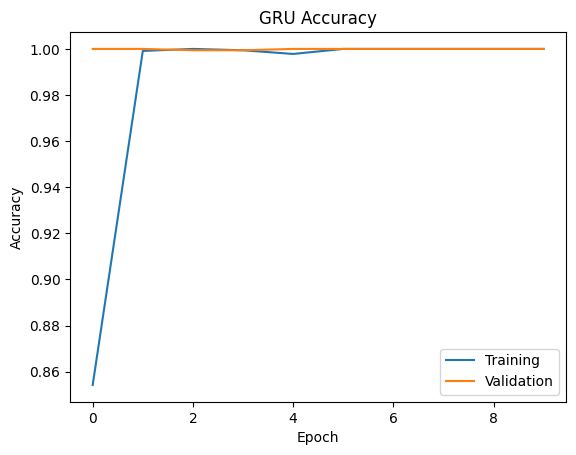

In [298]:
# ---------------------------
# Plot model accuracy
# ---------------------------
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('GRU Accuracy')
plt.legend()
plt.show()

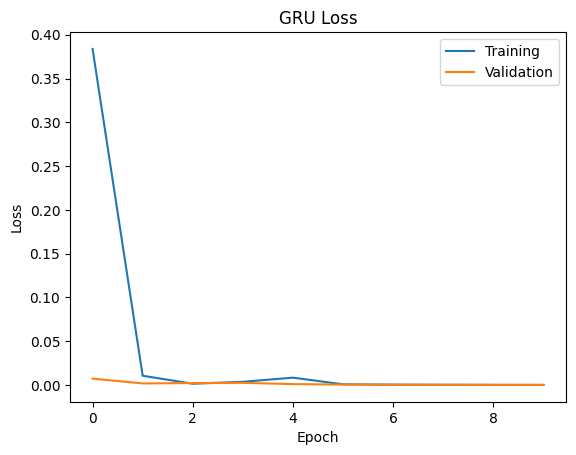

In [299]:
# ---------------------------
# Plot the loss
# ---------------------------
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('GRU Loss')
plt.legend()
plt.show()

X_test shape: (1718, 100, 6)
54/54 [==============================] - 0s 1ms/step


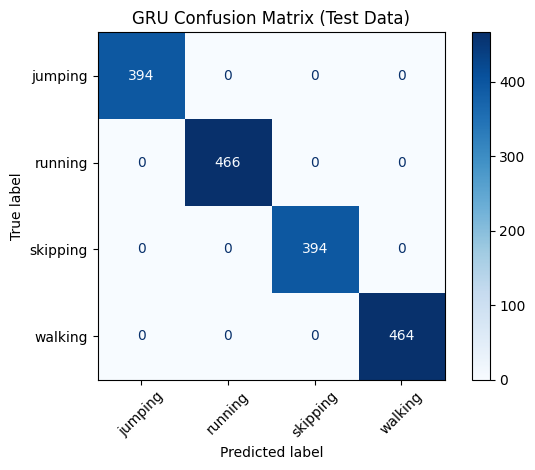

In [300]:
# ---------------------------
# Best model selected for Test data
# ---------------------------
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

test_data = pd.read_csv("ntest.csv")
x_test, y_test = create_windows(test_data, window_size, step_size)
y_test = label_encoder.transform(y_test) # Convert training labels from strings to integers
print("X_test shape:", x_test.shape)

y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# ---------------------------
# Create confusion matrix
# ---------------------------
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=label_encoder.classes_
)

disp.plot(cmap="Blues", values_format="d")
plt.title("GRU Confusion Matrix (Test Data)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [304]:
# ---------------------------
# Evaluate performance on continuos recording
# ---------------------------

features = ['ax', 'ay', 'az', 'gx', 'gy', 'gz']

# Load 90-second continuous recording
continuous_data = pd.read_csv("rjws.csv")

# Extract sensor data in the same feature order used during training
X = continuous_data[features].to_numpy(dtype=np.float32)

# Use the same fitted scaler as your final GRU model.
# Do not fit a new scaler on the continuous recording.
#X_scaled = scaler.transform(X)  # Remove this line if your final model used no scaling

# Create overlapping windows
x_continuous = np.array([
    X[i:i + window_size]
    for i in range(0, len(X) - window_size + 1, step_size)
])

print("Window shape:", x_continuous.shape)

# Predict the class probabilities for every window
probabilities = model.predict(x_continuous, verbose=0)

# Select the most likely class for each window
predicted_indices = np.argmax(probabilities, axis=1)

# Use the SAME label encoder that was fitted during training
predicted_labels = label_encoder.inverse_transform(predicted_indices)

#print("Predicted classes:", predicted_labels)
print("Predicted classes:", np.unique(predicted_labels))

Window shape: (961, 100, 6)
Predicted classes: ['jumping' 'running' 'skipping']


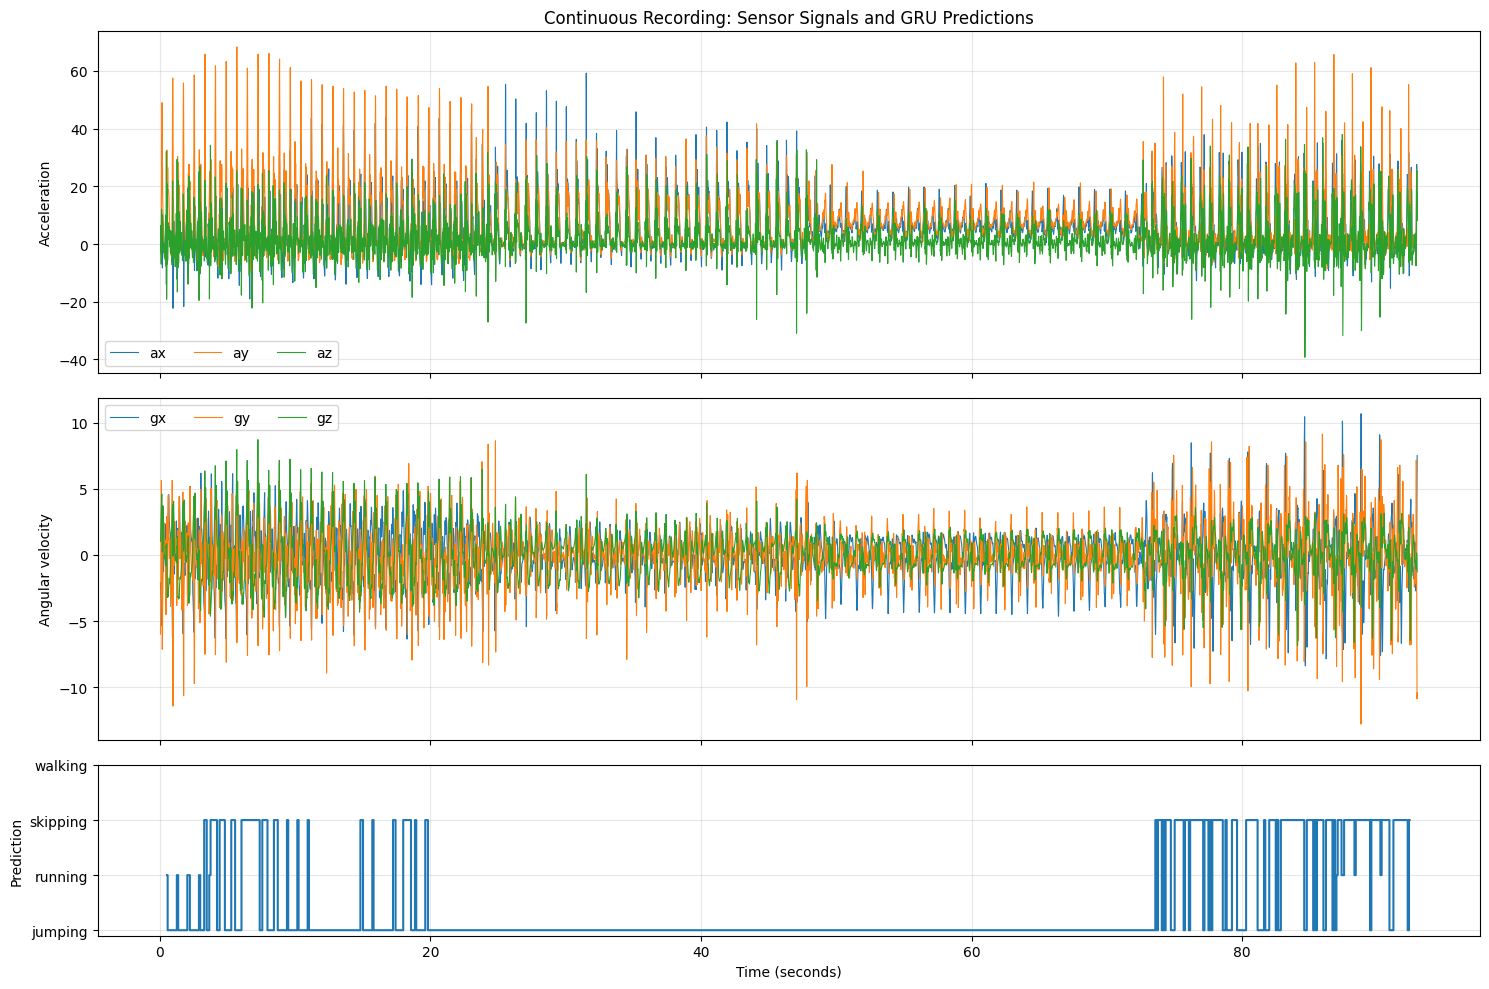

In [305]:
# Use the recording's time column if available.
time = continuous_data['time'].to_numpy()

# Assign each prediction to the centre of its window
window_times = np.array([
    time[i + window_size // 2]
    for i in range(0, len(X) - window_size + 1, step_size)
])

# Convert class names into numeric positions for plotting
class_names = list(label_encoder.classes_)
class_to_number = {name: i for i, name in enumerate(class_names)}
predicted_numbers = np.array([
    class_to_number[label] for label in predicted_labels
])

fig, axes = plt.subplots(
    3, 1, figsize=(15, 10), sharex=True,
    gridspec_kw={'height_ratios': [2, 2, 1]}
)

# Accelerometer
for col in ['ax', 'ay', 'az']:
    axes[0].plot(time, continuous_data[col], label=col, linewidth=0.8)

axes[0].set_ylabel("Acceleration")
axes[0].set_title("Continuous Recording: Sensor Signals and GRU Predictions")
axes[0].legend(ncol=3)
axes[0].grid(True, alpha=0.3)

# Gyroscope
for col in ['gx', 'gy', 'gz']:
    axes[1].plot(time, continuous_data[col], label=col, linewidth=0.8)

axes[1].set_ylabel("Angular velocity")
axes[1].legend(ncol=3)
axes[1].grid(True, alpha=0.3)

# Predicted movement
axes[2].step(
    window_times,
    predicted_numbers,
    where='mid',
    linewidth=1.5
)

axes[2].set_yticks(range(len(class_names)))
axes[2].set_yticklabels(class_names)
axes[2].set_ylabel("Prediction")
axes[2].set_xlabel("Time (seconds)")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

X_test shape: (3246, 100, 6)
102/102 [==============================] - 0s 1ms/step


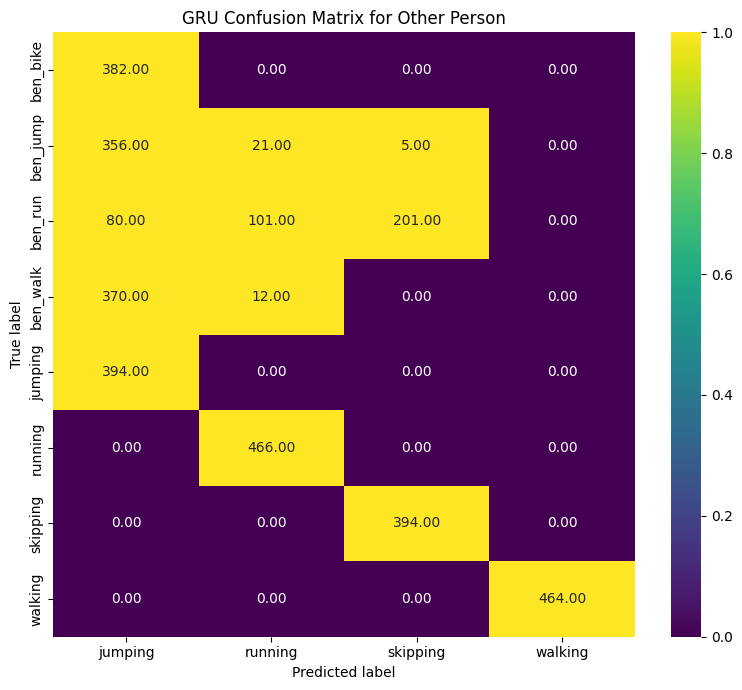

In [306]:
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 
# Generalize to another person's test set
#*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=*=* 
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

me_ben = pd.read_csv("Renamed_combined.csv", index_col=0) # Get training set

mbx_test, y_test = create_windows(me_ben, window_size, step_size)
t_activity = np.array(y_test)

print("X_test shape:", mbx_test.shape)

y_pred_probs = model.predict(mbx_test)
#predictions = np.argmax(y_pred_probs, axis=1)

# Convert predicted class indices back to class names
predicted_indices = np.argmax(y_pred_probs, axis=1)
predictions = label_encoder.inverse_transform(predicted_indices)

true_labels = [
    "ben_bike",
    "ben_jump",
    "ben_run",
    "ben_walk",
    "jumping",
    "running",
    "skipping",
    "walking"
]

trained_labels = [
    "jumping",
    "running",
    "skipping",
    "walking"
]

# Create an 8 x 4 confusion matrix
cm = np.zeros((len(true_labels), len(trained_labels)))

for i, true_label in enumerate(true_labels):
    for j, predicted_label in enumerate(trained_labels):
        cm[i, j] = np.sum(
            (t_activity == true_label) &
            (predictions == predicted_label)
        )


# Plot
plt.figure(figsize=(8, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt=".2f",
    xticklabels=trained_labels,
    yticklabels=true_labels,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("GRU Confusion Matrix for Other Person")
plt.tight_layout()
plt.show()
